In [187]:
#IMPORTS

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from scipy.signal import peak_widths

In [188]:
#DIRECTORIES AND SETUP

SOURCE_DIR = Path("Source")
SINGLE_DIR = Path("Single electron")

folders = {
    "source": SOURCE_DIR,
    "single_electron": SINGLE_DIR,
}
groups = ["Experiment", "Data", "Instruments"]

In [189]:
#FUNCTIONS

def gauss(x, A, mu, sigma, c):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2)) + c

def find_peak(spectrum, measurement_type, smooth_sigma=10, prominence=50):
    spectrum = spectrum.astype(float)
    smooth = gaussian_filter1d(spectrum, smooth_sigma)
    n = len(spectrum)

    if measurement_type == "single_electron":
        return int(np.argmax(smooth)) #highest point overall (argmax also works if the peak is at the edge)

    if measurement_type == "source":
        start = n // 4 #only look in the last 3/4
        peaks, _ = find_peaks(smooth[start:], prominence=prominence)
        if len(peaks) == 0:
            raise ValueError("No peak found; lower the prominence")
        best = peaks[np.argmax(smooth[start:][peaks])]
        return int(best + start) #add the offset back
    
    raise ValueError("measurement_type must be 'source' or 'single_electron'")

def plot(measurement_type, scintillator):
    plt.figure()
    plt.plot(data[measurement_type][scintillator]["channels"], data[measurement_type][scintillator]["spectrum"])
    plt.title(f"{measurement_type} / {scintillator}")
    plt.xlabel("Channel"); plt.ylabel("Counts")
    plt.show()

def fit_peak(spectrum, centre, measurement_type, smooth_sigma=None):
    spectrum = spectrum.astype(float)
    if smooth_sigma is None:
        smooth_sigma = 100 if measurement_type == "single_electron" else 10

    smooth = gaussian_filter1d(spectrum, 100)
    search_start = len(spectrum) // 8

    peaks, _ = find_peaks(spectrum[:search_start])
    if len(peaks) == 0:
        raise ValueError("No sharp peak found in first eighth")
    first_peak = peaks[np.argmax(spectrum[peaks])]

    later_peaks, _ = find_peaks(smooth[search_start:])
    later_peaks += search_start
    later_peaks = later_peaks[later_peaks > first_peak]

    if len(later_peaks) == 0:
        raise ValueError("No later peak found")

    peak = later_peaks[np.argmin(abs(later_peaks - centre))]
    minimum = first_peak + np.argmin(smooth[first_peak:peak + 1])

    right = len(spectrum)
    x = np.arange(minimum, len(spectrum))
    y = spectrum[minimum:]

    p0 = [max(smooth[peak] - smooth[minimum], 1), peak, max((peak - minimum) / 4, 1), smooth[minimum]]

    popt, pcov = curve_fit(gauss, x, y, p0=p0, bounds=([0, minimum, 1e-6, -np.inf], [np.inf, right, len(spectrum), np.inf]), maxfev=30000)

    A, mu, sigma, c = popt
    errors = np.sqrt(np.diag(pcov))

    return {"A": A, "mu": mu, "sigma": sigma, "c": c,
            "fwhm": 2.355 * abs(sigma), "errors": errors,
            "fwhm_error": 2.355 * errors[2], "minimum": minimum,
            "x": x, "y": y, "popt": popt, "pcov": pcov}

In [190]:
#LOADING DATA, FINDING IMPORTANT PEAKS

data = {}
for name, folder in folders.items():
    data[name] = {}
    for f in sorted(folder.glob("*.nc")):
        key = f.stem.split("_")[-1]
        if key in data[name]:
            print(f"Warning: key '{key}' already used in {name}, skipping {f.name}")
            continue

        with xr.open_dataset(f, group="Data", mask_and_scale=False) as ds:
            counts = ds["MCA"].values #(1, 8000), uint32
        spectrum = counts[0].astype(float) #float avoids uint32 wraparound
        channels = np.arange(len(spectrum))
        centre = find_peak(spectrum, name)
        entry = {"counts": counts, "spectrum": spectrum, "channels": channels, "centre": centre}
        data[name][key] = entry

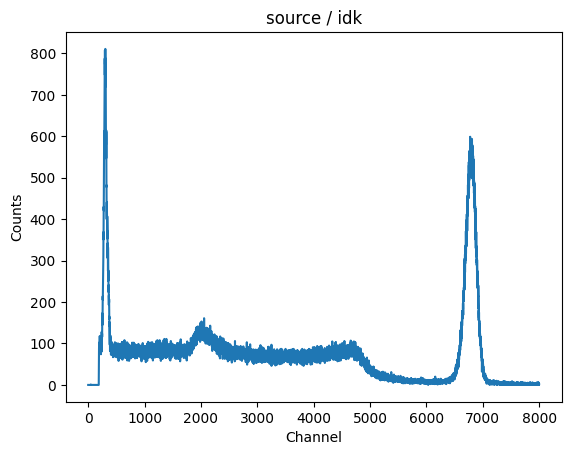

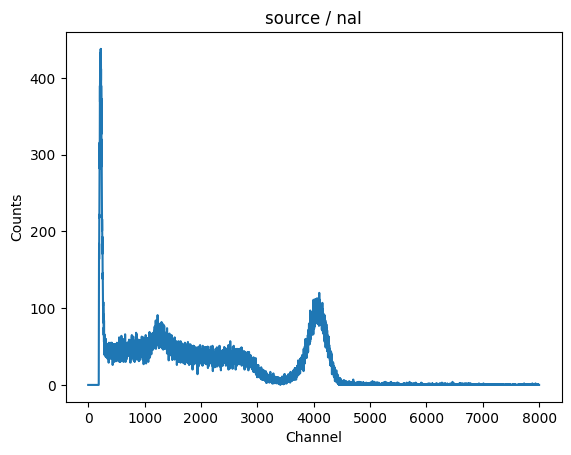

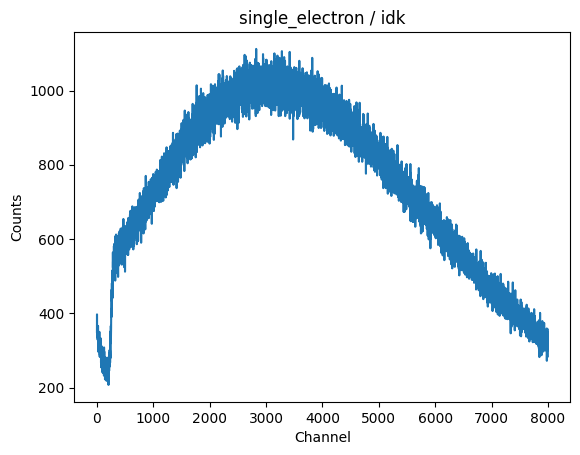

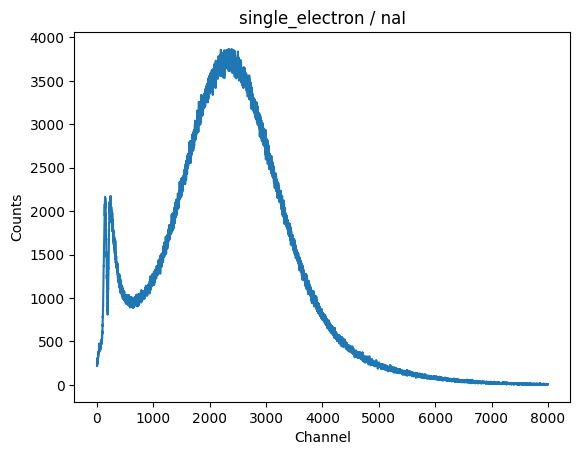

In [191]:
#PLOTS

for measurement_type, files in data.items():
    for scintillator, e in files.items():
        plot(measurement_type, scintillator)

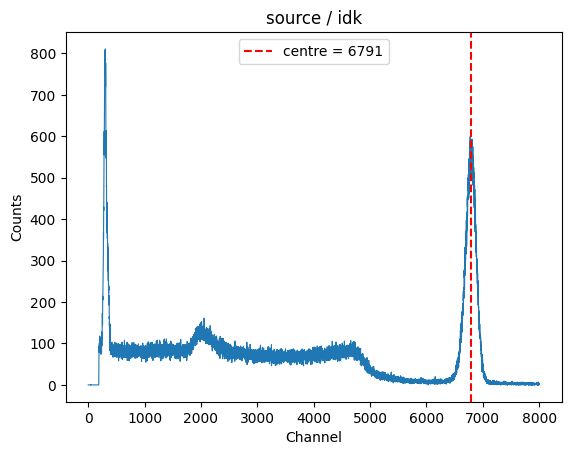

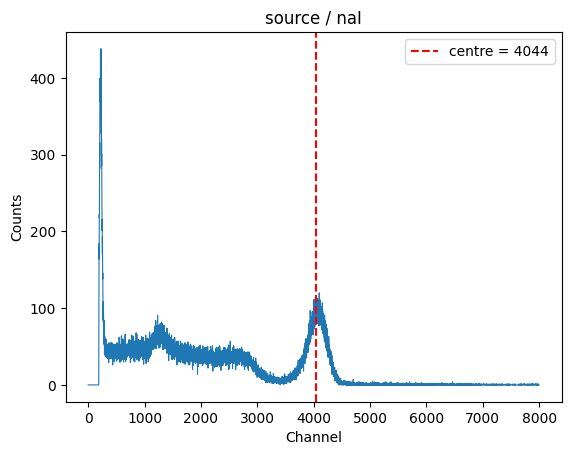

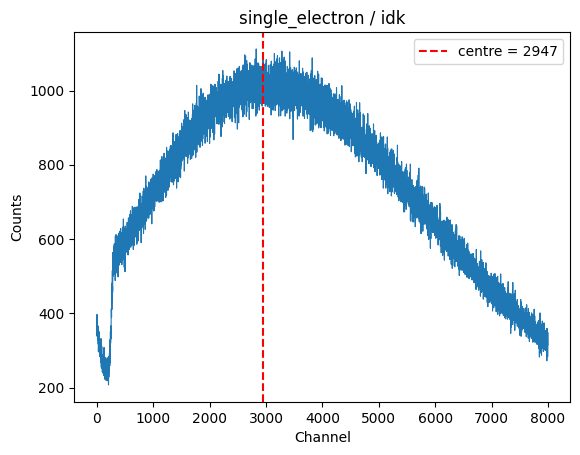

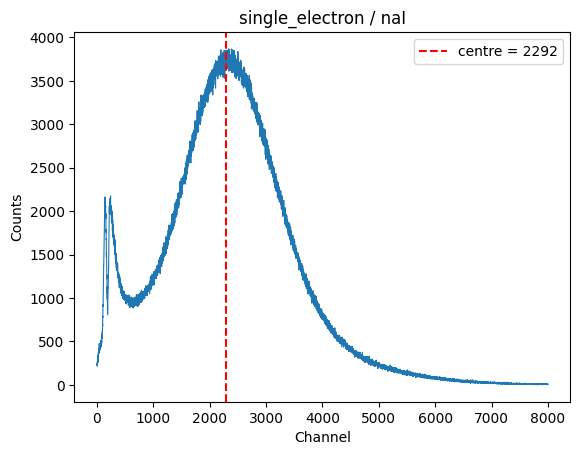

In [192]:
for name, files in data.items():
    for key, e in files.items():
        plt.figure()
        plt.plot(e["channels"], e["spectrum"], lw=0.8)
        plt.axvline(e["centre"], color="r", ls="--", label=f"centre = {e['centre']}")
        plt.legend()
        plt.title(f"{name} / {key}")
        plt.xlabel("Channel")
        plt.ylabel("Counts")
        plt.show()

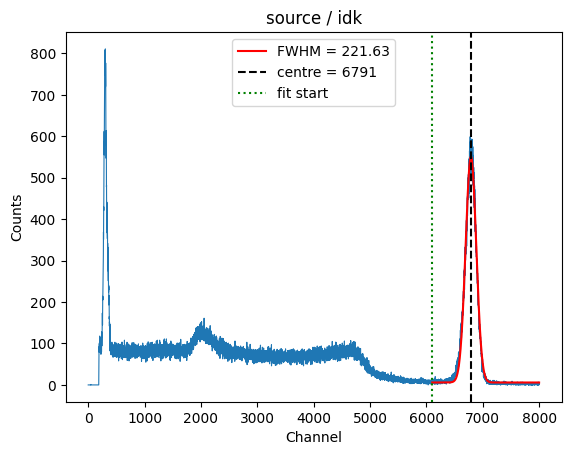

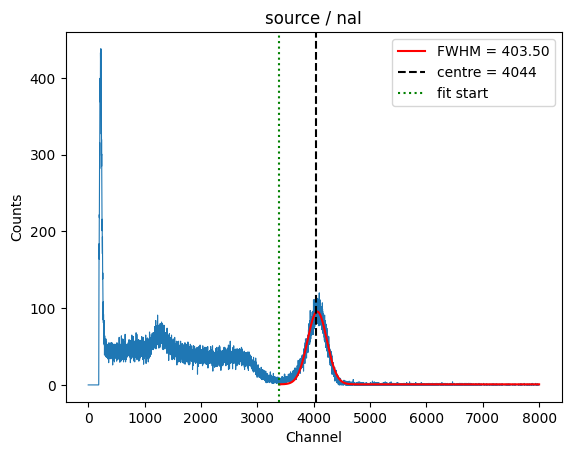

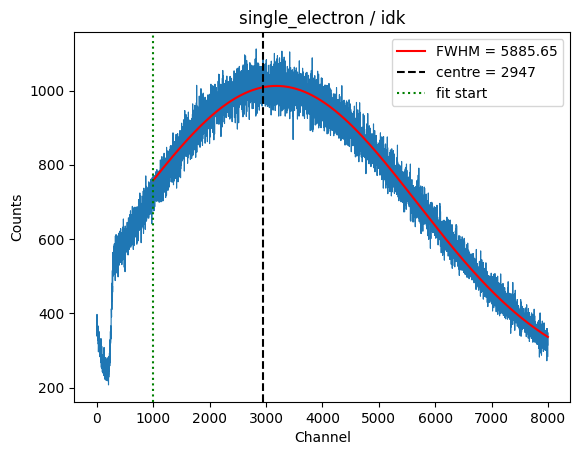

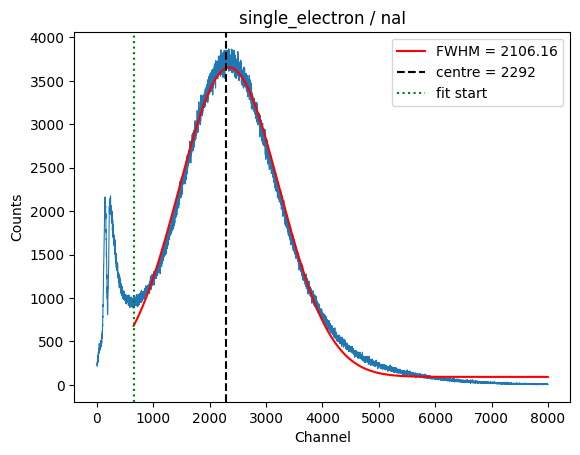

In [193]:
for name, files in data.items():
    for key, e in files.items():
        try:
            e["fit"] = fit_peak(e["spectrum"], e["centre"], name)
        except (ValueError, RuntimeError) as err:
            print(f"Fit failed for {name}/{key}: {err}")
            continue

        fit = e["fit"]
        plt.figure()
        plt.plot(e["channels"], e["spectrum"], lw=0.8)
        plt.plot(fit["x"], gauss(fit["x"], *fit["popt"]), "r-", label=f"FWHM = {fit['fwhm']:.2f}")
        plt.axvline(e["centre"], color="k", ls="--", label=f"centre = {e['centre']}")
        plt.axvline(fit["minimum"], color="g", ls=":", label="fit start")
        plt.legend()
        plt.title(f"{name} / {key}")
        plt.xlabel("Channel")
        plt.ylabel("Counts")
        plt.show()

In [194]:
for name, files in data.items():
    for key, e in files.items():
        if "fit" in e:
            print(
                name,
                key,
                "Detected centre:", e["centre"],
                "Fitted centre:", f"{e['fit']['mu']:.2f} ± {e['fit']['errors'][1]:.2f}",
                "FWHM:", f"{e['fit']['fwhm']:.2f} ± {e['fit']['fwhm_error']:.2f}"
            )

source idk Detected centre: 6791 Fitted centre: 6789.52 ± 0.22 FWHM: 221.63 ± 0.54
source naI Detected centre: 4044 Fitted centre: 4063.09 ± 0.53 FWHM: 403.50 ± 1.29
single_electron idk Detected centre: 2947 Fitted centre: 3182.16 ± 3.15 FWHM: 5885.65 ± 25.60
single_electron naI Detected centre: 2292 Fitted centre: 2348.15 ± 0.76 FWHM: 2106.16 ± 2.15
